In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
import os
import shap

from datetime import datetime
from scipy.stats import loguniform
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import VarianceThreshold, SelectKBest, chi2, RFE, RFECV, mutual_info_classif, f_classif, SequentialFeatureSelector
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV, train_test_split, RandomizedSearchCV, TunedThresholdClassifierCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.metrics import roc_curve, roc_auc_score, accuracy_score, confusion_matrix, recall_score, make_scorer, balanced_accuracy_score
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.utils.class_weight import compute_class_weight
from sklearn.tree import DecisionTreeClassifier

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from imblearn.ensemble import EasyEnsembleClassifier, BalancedRandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier

from pre_processing import process
from iv_and_weo import filter_on_iv
from lmt import LogisticTreeClassifier


In [35]:
# Import data
raw_data = pd.read_csv("data_case2.csv") 

# Pre-process data
X, y = process(raw_data, column_nan_threshold=0.1, row_nan_threshold=0.1)

In [36]:
# Feature selection with information value (optional)
# selected_features, X = filter_on_iv(pd.concat([X, y], axis=1), target ='target_binary', n_features_to_select = 50)
# print(selected_features)

In [37]:
# print(X)

In [38]:
# Set up pipeline (which include pre-processing steps that should not be done using the test data)
cat_cols = [col for col in X.columns if X[col].dtype == 'object']
num_cols = [col for col in X.columns if col not in cat_cols]

numerical_transformer = Pipeline([
    # ("variance_threshold", VarianceThreshold(threshold=0.3)),  # Apply VarianceThreshold to numerical data
    ("imputer", SimpleImputer(strategy="median")),  # Impute missing values with the median
    ("scaler", StandardScaler()),  # Scale numerical features
    ("select", SelectKBest(score_func=f_classif, k=44)) # Select k best numerical features based on f-score
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),  # Mode for categorical
    ("encoder", OneHotEncoder(handle_unknown="ignore")),  # One-hot encode
    ("select", SelectKBest(score_func=chi2, k=6)) # Select k best categorical features based on chi-square
])

preprocessor = ColumnTransformer([
    ("num", numerical_transformer, num_cols),
    ("cat", categorical_transformer, cat_cols)
])

In [51]:
# --- TOGGLES ---
model_choice = "logistic"       # "logistic", "svm", "logistic_tree", "neural_network"
search_type = "random"          # "random" or "grid"
add_interactions = False
use_rfe = True                  # Set to True to use Recursive Feature Elimination
use_mi = False                  # Set to True to use Mutual Information as feature selection criteria
use_smote = False               # Enable/disable SMOTE
use_tuning = True               # Enable/disable hyperparameter search
use_calibration = False         # Enable/disable probability calibration
optimize_threshold = False       # Enable/disable dynamic thresholding
use_custom_scorer = False      # Enable/disable custom scoring (recall + AUC)
use_SHAP = True                 # Enable SHAP values

# --- CLASSIFIER & PARAM GRID SETUP ---
if model_choice.lower() == "logistic":
    base_classifier = LogisticRegression(
        class_weight="balanced",
        # class_weight={0: 1, 1: 25},
        penalty = None,
        solver="lbfgs",
        max_iter=3000
    )
    param_grid = {
        "classifier__C": np.logspace(-3, 3, 10),
        "classifier__l1_ratio": np.linspace(0.1, 0.9, 10)
    }

elif model_choice.lower() == "svm":
    base_classifier = SVC(
        kernel="rbf",
        C=0.01,                        # Small C encourages margin, helps generalization
        gamma=0.003,                   # Slightly wider kernel (tuned previously)
        class_weight={0: 1, 1: 10},    # Heavily favors the minority class → improves sensitivity
        probability=True,
        random_state=42
    )

    param_grid = {
        #     "classifier__class_weight": [
        #     {0: 1, 1: 3},
        #     {0: 1, 1: 5},
        #     {0: 1, 1: 8},
        #     {0: 1, 1: 10}
        # ]
        "classifier__C": np.logspace(-3, 3, 10),
        "classifier__gamma": ["scale", "auto"] + list(np.logspace(-15, 3, num=10))
    }

elif model_choice.lower() == "logistic_tree":
    base_classifier = LogisticTreeClassifier(penalty="elasticnet", solver="saga", logreg_max_iter=10000, use_lightgbm=True)
    param_grid = {
        "classifier__logreg_C": np.logspace(-3, 3, 10),
        "classifier__max_depth": [3, 5, 7, 10],
        "classifier__min_samples_leaf": [50, 100, 200],
        "classifier__l1_ratio": np.linspace(0.1, 0.9, 10)
    }

elif model_choice.lower() == "neural_network":
    base_classifier = MLPClassifier(hidden_layer_sizes=[20, 20], activation='relu', solver='adam', max_iter=1000, random_state=42, learning_rate_init=0.02)
    param_grid = {
        "classifier__hidden_layer_sizes": [5, 10, 20, 30, 40, [20, 20]],
        "classifier__activation": ["tanh", "relu"],
        #"classifier__solver": ["sgd", "adam"],
        #"classifier__alpha": [0.0001, 0.05],
        #"classifier__learning_rate": ["constant", "adaptive"]
    }

elif model_choice.lower() == "random_forest":
    base_classifier = BalancedRandomForestClassifier(n_estimators=100, random_state=42)
    param_grid = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__max_depth': [None, 10, 20, 30],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 5, 10, 20],
    'classifier__max_features': ['sqrt', 'log2', None]
}

elif model_choice.lower() == "ada_boost":
    base_estimator = AdaBoostClassifier(estimator=DecisionTreeClassifier(), random_state=42)
    base_classifier = EasyEnsembleClassifier(estimator=base_estimator, random_state=42)
    param_grid = {
    'classifier__n_estimators': [10, 20, 30, 40, 50],  # Number of AdaBoost learners in the ensemble
    'classifier__estimator__n_estimators': [50, 100, 200],  # Number of estimators in AdaBoost
    'classifier__estimator__learning_rate': [0.001, 0.01, 0.1, 1.0],  # Learning rate for AdaBoost
    'classifier__estimator__estimator__max_depth': [1, 3, 5, 7],  # Max depth of decision trees
    'classifier__estimator__estimator__min_samples_split': [2, 5, 10],  # Min samples to split
    'classifier__estimator__estimator__min_samples_leaf': [2, 5, 10, 20, 50] 
}

else:
    raise ValueError("model_choice must be 'logistic', 'svm', or 'logistic_tree'")

# --- Custom Scorer: prioritizes sensitivity (recall) and adds AUC ---
def combined_score(y_true, y_pred):
    recall = recall_score(y_true, y_pred)
    try:
        auc = roc_auc_score(y_true, y_pred)
    except:
        auc = 0.5
    return 0.9 * recall + 0.1 * auc

custom_scorer = make_scorer(combined_score, response_method="predict")



✨ Iteration 1
🔍 Running hyperparameter search
Fitting 5 folds for each of 40 candidates, totalling 200 fits


C:\Users\Siem.Poppe\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=None)
  warnings.warn(
C:\Users\Siem.Poppe\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1207: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(



✨ Iteration 2
🔍 Running hyperparameter search
Fitting 5 folds for each of 40 candidates, totalling 200 fits


C:\Users\Siem.Poppe\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=None)
  warnings.warn(
C:\Users\Siem.Poppe\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1207: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(



✨ Iteration 3
🔍 Running hyperparameter search
Fitting 5 folds for each of 40 candidates, totalling 200 fits


...


✨ Iteration 4
🔍 Running hyperparameter search
Fitting 5 folds for each of 40 candidates, totalling 200 fits


C:\Users\Siem.Poppe\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=None)
  warnings.warn(
C:\Users\Siem.Poppe\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1207: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(



✨ Iteration 5
🔍 Running hyperparameter search
Fitting 5 folds for each of 40 candidates, totalling 200 fits


C:\Users\Siem.Poppe\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=None)
  warnings.warn(
C:\Users\Siem.Poppe\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1207: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(



📊 Final Averaged Results
Model: LogisticRegression
Accuracy: 0.6770
AUC: 0.7217
Sensitivity: 0.6513
Specificity: 0.6796


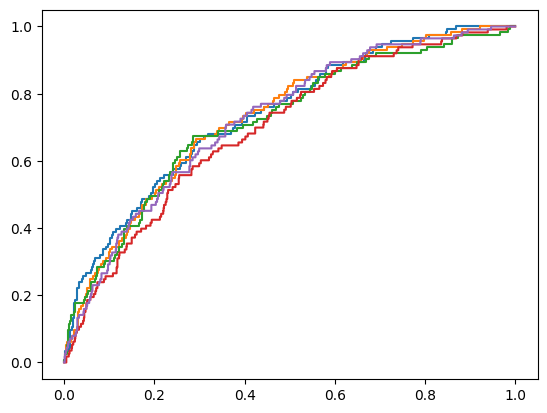

In [52]:
# --- TRACKING METRICS ---
test_accuracies = []
test_auc_scores = []
test_sensitivity = []
test_specificity = []

# --- MAIN LOOP ---

if use_rfe:
    X_processed = preprocessor.fit_transform(X, y)

    selector = RFE(estimator=LogisticRegression(penalty='l1', solver='liblinear'), n_features_to_select=10, step=1)
    selector.fit(X_processed, y)

    selected_mask = selector.support_
    X_selected = X_processed[:, selected_mask]
    X = selector.transform(X_processed)

    if add_interactions:
        poly = PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)
        X_interactions = poly.fit_transform(X_selected)

        feature_names = poly.get_feature_names_out()
        interaction_mask = np.array([' ' in name for name in feature_names])
        X_interaction_terms = X_interactions[:, interaction_mask]
        interaction_feature_names = feature_names[interaction_mask]

        base_model = LogisticRegression(solver='liblinear')
        selector_interactions = SequentialFeatureSelector(base_model, n_features_to_select=5, direction='backward')
        selector_interactions.fit(X_interaction_terms, y)

        selected_interaction_mask = selector_interactions.support_
        X_top_interactions = X_interaction_terms[:, selected_interaction_mask]
        top_interaction_feature_names = interaction_feature_names[selected_interaction_mask]

        print("Selected interaction features:")
        for name in top_interaction_feature_names:
            print(" -", name)

        X = np.hstack((X_selected, X_top_interactions))

for run in range(5):
    print(f"\n✨ Iteration {run + 1}")

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, shuffle=True, random_state=run * 2)
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=run)

    steps = []
    if not use_rfe:
        steps = [("preprocessor", preprocessor)]

    if use_smote:
        steps.append(("smote", SMOTE(random_state=42)))

    if use_mi:
        steps.append(("feature_selection", SelectKBest(mutual_info_classif, k=30)))

    steps.append(("classifier", base_classifier))
    pipeline = ImbPipeline(steps)

    if use_tuning and param_grid is not None:
        print("🔍 Running hyperparameter search")
        search = RandomizedSearchCV(
            estimator=pipeline,
            param_distributions=param_grid,
            n_iter=40,
            cv=skf,
            scoring=custom_scorer if use_custom_scorer else make_scorer(roc_auc_score, response_method="predict"),
            n_jobs=-1,
            verbose=1,
            random_state=run
        )
        search.fit(X_train, y_train)
        best_model = search.best_estimator_
    else:
        print("⚙️ Fitting model without tuning")
        pipeline.fit(X_train, y_train)
        best_model = pipeline

    if use_calibration and model_choice == "svm" and not use_tuning:
        print("✅ Applying probability calibration")
        calibrated = CalibratedClassifierCV(best_model.named_steps['classifier'], cv="prefit")
        calibrated.fit(best_model.named_steps['preprocessor'].transform(X_train), y_train)
        best_model = Pipeline([
            ("preprocessor", best_model.named_steps['preprocessor']),
            ("classifier", calibrated)
        ])

    if optimize_threshold:
        best_model.fit(X_train, y_train)
        y_train_prob = best_model.predict_proba(X_train)[:, 1]
        thresholds = np.linspace(0.01, 0.99, 100)
        best_threshold = 0.5
        best_auc = -1
        for threshold in thresholds:
            y_train_pred = (y_train_prob >= threshold).astype(int)
            auc = roc_auc_score(y_train, y_train_pred)
            if auc > best_auc:
                best_auc = auc
                best_threshold = threshold
        y_test_prob = best_model.predict_proba(X_test)[:, 1]
        y_test_pred = (y_test_prob >= best_threshold).astype(int)
    else:
        y_test_prob = best_model.predict_proba(X_test)[:, 1]
        custom_threshold = 0.5
        y_test_pred = (y_test_prob >= custom_threshold).astype(int)

    test_accuracy = accuracy_score(y_test, y_test_pred)
    test_auc = roc_auc_score(y_test, y_test_prob)
    tn, fp, fn, tp = confusion_matrix(y_test, y_test_pred).ravel()
    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)

    test_accuracies.append(test_accuracy)
    test_auc_scores.append(test_auc)
    test_sensitivity.append(sensitivity)
    test_specificity.append(specificity)

    fpr, tpr, _ = roc_curve(y_test, y_test_prob)
    plt.plot(fpr, tpr, label=f"Run {run+1} (AUC = {test_auc:.3f})")

if use_SHAP:
    model_name_lower = model_choice.lower()
    supported_models = ["logistic", "svm"]

    if model_name_lower in supported_models:
        print("\n🧠 Explaining model with SHAP...")
        try:
            model = best_model.named_steps["classifier"]
            X_sample_raw = X_test[:100]

            if use_rfe:
                # No preprocessor in pipeline → data is already transformed
                X_sample = pd.DataFrame(X_sample_raw)  # already numeric
            else:
                # Preprocessor exists → transform raw data
                X_sample = pd.DataFrame(
                    best_model.named_steps["preprocessor"].transform(X_sample_raw),
                    columns=best_model.named_steps["preprocessor"].get_feature_names_out()
                )

            if model_name_lower == "logistic":
                explainer = shap.Explainer(model, X_sample)
            elif model_name_lower == "svm":
                explainer = shap.KernelExplainer(model.predict_proba, X_sample)

            shap_values = explainer(X_sample)
            shap.summary_plot(shap_values, X_sample)

        except Exception as e:
            print(f"⚠️ SHAP explanation failed: {e}")
    else:
        print(f"ℹ️ SHAP is not supported for model '{model_choice}'. Skipping.")    


# --- RESULTS ---
print("\n📊 Final Averaged Results")
print(f"Model: {type(best_model.named_steps['classifier']).__name__}")
print(f"Accuracy: {np.mean(test_accuracies):.4f}")
print(f"AUC: {np.mean(test_auc_scores):.4f}")
print(f"Sensitivity: {np.mean(test_sensitivity):.4f}")
print(f"Specificity: {np.mean(test_specificity):.4f}")



🧠 Explaining model with SHAP...


C:\Users\Siem.Poppe\AppData\Local\Temp\ipykernel_34092\1073604657.py:27: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_sample)


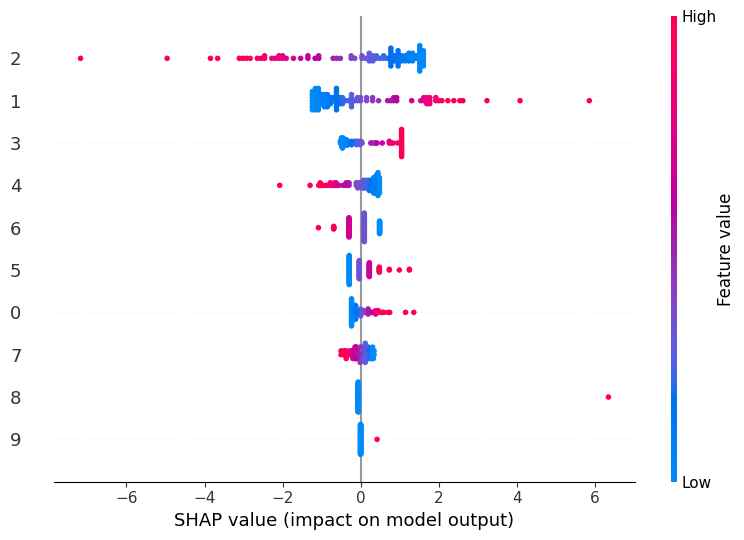

0 → num__v_13
1 → num__v_17
2 → num__v_28
3 → num__v_91
4 → num__v_118
5 → num__v_394
6 → num__v_483
7 → num__v_1448
8 → cat__v_1378_value_82
9 → cat__v_1469_value_5
{'classifier__l1_ratio': np.float64(0.1), 'classifier__C': np.float64(0.021544346900318832)}
Number of non-zero coefficients: 10


In [55]:
# Get all preprocessed feature names
all_feature_names = preprocessor.get_feature_names_out()

# Apply the mask to get only selected feature names
selected_feature_names = all_feature_names[selector.support_]

# Print out mapping
for idx, name in enumerate(selected_feature_names):
    print(f"{idx} → {name}")
        


# Compute mean test socres
mean_test_accuracy = np.mean(test_accuracies)
mean_test_auc = np.mean(test_auc_scores)
mean_test_sensitivity = np.mean(test_sensitivity)
mean_test_specificity = np.mean(test_specificity)

# Safely retrieve best param info if tuning was used
if use_tuning:
    best_params = search.best_params_
    best_score = search.best_score_
else:
    best_params = "No tuning"
    best_score = "N/A"

print(best_params)

classifier = best_model.named_steps['classifier']
coefficients = classifier.coef_
non_zero_coefficients = np.count_nonzero(coefficients)
print(f"Number of non-zero coefficients: {non_zero_coefficients}")

In [44]:
# Save best results to a file
results_file = "results.json"

if os.path.exists(results_file):
    with open(results_file, "r") as f:
        results = json.load(f) 
else:
    results = {}

model_name = f"{type(pipeline.named_steps['classifier']).__name__} - {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}"

new_results = { 
    # "best_params": grid_search.best_params_,
    # "best_score": grid_search.best_score_,
    "test_accuracy": mean_test_accuracy,  
    "test_auc": mean_test_auc, 
    "auc_per_run": test_auc_scores
    "test_sensitivity": mean_test_sensitivity,
    "test_specificity": mean_test_specificity,
    "timestamp": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    "note": "Logistic regression with l1 penalty, with feature selection, with RFE"
}

results[model_name] = new_results

with open(results_file, "w") as f:
    json.dump(results, f, indent=4)

SyntaxError: invalid syntax (3834224276.py, line 18)

In [ ]:
# Print summary
print(f"\nModel: {model_name}")
print(f"Test Accuracy: {mean_test_accuracy:.4f}")
print(f"Test AUC: {mean_test_auc:.4f}")
print(f"Test Sensitivity: {mean_test_sensitivity:.4f}")
print(f"Test Specificity: {mean_test_specificity:.4f}")
print(f"Best Params: {best_params}")
print(y.value_counts(normalize=True))
